In [192]:
import pandas as pd
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from collections import defaultdict
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from copy import copy
from collections import Counter
from plottable import ColumnDefinition, Table
from plottable.cmap import normed_cmap
from plottable.plots import image
from scipy.stats import poisson
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor

In [193]:
df = pd.read_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\Big Dataset.xlsx", index_col=0)

In [194]:
pd.set_option('display.max_columns', None)
df

,date,comp,season,round,HT,AT,result,home points,away points,home GF,away GF,HT GS,AT GS,home GA,away GA,HT GC,AT GC,home xG,away xG,home xGA,away xGA,HT AdjGD,AT AdjGD,HT AdjGD form 5,AT AdjGD form 5,HT GD form 5,AT GD form 5,HT constant GD form 5,AT constant GD form 5,HT xGD form 5,AT xGD form 5,HT constant xGD form 5,AT constant xGD form 5,HT points form 5,AT points form 5,HT constant points form 5,AT constant points form 5,HT avg pos,AT avg pos,HT prev pos,AT prev pos,HT prev exp pos,AT prev exp pos,HT prev points,AT prev points,HT prev GD,AT prev GD,HT prev xGD,AT prev xGD,AT Away GS form 10,AT Away GC form 10,AT Away points form 10,AT Away constant points form 10,AT Away GF form 10,AT Away GA form 10,AT Away xG form 10,AT Away xGA form 10,HT Home points form 10,HT Home constant points form 10,HT Home GF form 10,HT Home GA form 10,HT Home xG form 10,HT Home xGA form 10,HT Home GS form 10,HT Home GC form 10,HT Market Value,AT Market Value,HT Wages,AT Wages
0,2018-08-03,Championship,2018,Matchweek 1,Reading,Derby County,AW,0.0,0.9,0.24,1.24,0.19,0.59,3.02,2.02,2.37,1.97,0.14,-0.06,1.72,1.92,-1.915,-1.115,NaN,NaN,-3.38,-1.38,-1.0,-1.0,NaN,NaN,-1.0,-1.0,0.12,0.42,1.0,1.0,33.333333,26.666667,40,26,45,45,13.2,22.5,-103.88,-59.88,-80.0,-80.0,NaN,NaN,0.33,1.0,0.24,2.22,NaN,NaN,0.30,1.0,0.34,2.82,NaN,NaN,NaN,NaN,66250000.0,9.430000e+07,NaN,NaN
1,2018-08-04,Championship,2018,Matchweek 1,Birmingham City,Norwich City,D,0.3,0.3,1.24,1.24,0.89,1.14,3.02,3.02,2.92,2.67,0.54,1.04,2.82,2.32,-1.765,-1.265,NaN,NaN,-2.38,-2.78,-1.0,-1.0,NaN,NaN,-1.0,-1.0,0.36,0.30,1.0,1.0,36.000000,27.000000,39,34,45,45,13.8,18.0,-111.88,-92.88,-80.0,-80.0,NaN,NaN,0.33,1.0,0.44,2.82,NaN,NaN,0.48,1.0,0.54,2.12,NaN,NaN,NaN,NaN,42500000.0,8.630000e+07,NaN,NaN
2,2018-08-04,Championship,2018,Matchweek 1,Brentford,Rotherham Utd,HW,0.9,0.0,4.24,0.24,2.99,0.04,2.02,6.02,1.82,4.77,1.74,-0.16,1.62,3.52,1.435,-4.465,NaN,NaN,-1.78,NaN,-1.0,NaN,NaN,NaN,-1.0,NaN,0.48,NaN,1.0,NaN,29.333333,44.333333,30,45,45,45,20.7,15.0,-71.88,-80.00,-80.0,-80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.48,1.0,0.74,1.92,NaN,NaN,NaN,NaN,76350000.0,1.158000e+07,NaN,NaN
3,2018-08-04,Championship,2018,Matchweek 1,Bristol City,Nott'ham Forest,D,0.3,0.3,0.24,0.24,-0.06,0.09,2.02,2.02,1.87,1.72,-0.36,-0.06,1.72,1.42,-1.665,-1.365,NaN,NaN,-1.78,-1.38,-1.0,-1.0,NaN,NaN,-1.0,-1.0,0.30,0.42,1.0,1.0,35.333333,38.000000,31,37,45,45,20.1,15.9,-72.88,-95.88,-80.0,-80.0,NaN,NaN,0.27,1.0,0.24,2.32,NaN,NaN,0.45,1.0,1.34,2.52,NaN,NaN,NaN,NaN,72550000.0,8.310000e+07,NaN,NaN
4,2018-08-04,Championship,2018,Matchweek 1,Ipswich Town,Blackburn,D,0.3,0.3,1.24,1.24,0.54,1.14,3.02,3.02,2.92,2.32,-0.16,1.04,2.82,1.62,-2.115,-0.915,NaN,NaN,-1.78,NaN,-1.0,NaN,NaN,NaN,-1.0,NaN,0.42,NaN,1.0,NaN,31.666667,41.000000,32,45,45,45,18.0,15.0,-84.88,-80.00,-80.0,-80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.30,1.0,-0.16,2.32,NaN,NaN,NaN,NaN,26850000.0,3.475000e+07,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5967,2025-05-06,Premier League,2024,Matchweek 38,Newcastle Utd,Everton,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.333333,16.000000,7,12,5,10,60.0,48.0,23.00,-11.00,14.8,-1.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,659650000.0,3.238000e+08,1900000.0,1183500.0
5968,2025-05-06,Premier League,2024,Matchweek 38,Nott'ham Forest,Chelsea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.000000,7.000000,17,6,12,4,36.0,63.0,-18.00,14.00,-3.2,16.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,376900000.0,1.110000e+09,1203462.0,3667500.0
5969,2025-05-06,Premier League,2024,Matchweek 38,Southampton,Arsenal,NaN,NaN

In [195]:
champ = df[(df['comp'] == 'Championship') & (df['season'] == 2023)]
champ.reset_index(drop=True, inplace=True)
df_future = df[df['season'] == 2024]
df_future.reset_index(drop=True, inplace=True)
df = df[(df['comp'] == 'Premier League') & (df['season'] != 2024)]
df.reset_index(drop=True, inplace=True)

In [196]:
df.dropna(inplace=True)

C:\Users\dmsta\AppData\Local\Temp\ipykernel_19540\1379821321.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(inplace=True)


In [197]:
df.reset_index(drop=True, inplace=True)

In [202]:
def get_data_split(df, date):
    train = df[df["date"] < date]
    test = df[df["date"] > date]
    return train, test

def get_feature_split(train, test, target,predictors):
    trainX = train[predictors]
    trainY = train[target]
    testX = test[predictors]
    testY = test[target]
    return trainX, trainY, testX, testY

def get_scaled_data(trainX, testX):
    scaler = StandardScaler()
    scaler.fit(trainX)
    trainX_scaled = scaler.transform(trainX, copy=True)
    testX_scaled = scaler.transform(testX, copy=True)
    return trainX_scaled, testX_scaled

def fit_poisson_model(alpha,intercept,max_iter,trainX, trainY):
    model = PoissonRegressor(alpha = alpha,fit_intercept=intercept, max_iter=max_iter).fit(trainX, trainY)
    return model

def calculate_goal_probabilities(lambda_param, max_goals=8):
    probabilities = [poisson.pmf(i, lambda_param) for i in range(max_goals)]
    probabilities.append(1 - sum(probabilities))  # Probability of max_goals or more
    return probabilities

In [203]:
train, test = get_data_split(df, "2023-08-01")

In [204]:
expected = 'Yes'
if expected == 'Yes':
    home_predictors = ['HT AdjGD form 5', 'AT AdjGD form 5', 'HT Home GS form 10',
        'HT Home GC form 10', 'AT Away GS form 10', 'AT Away GC form 10',
        'HT prev points','AT prev points','HT Market Value', 'AT Market Value']
    away_predictors = ['HT AdjGD form 5', 'AT AdjGD form 5', 'HT Home GS form 10',
        'HT Home GC form 10', 'AT Away GS form 10', 'AT Away GC form 10',
        'HT prev points','AT prev points','HT Market Value', 'AT Market Value']
else:
    home_predictors = ['HT GD form 5', 'AT GD form 5','HT Home GF form 10','HT Home GA form 10',
        'AT Away GF form 10','AT Away GA form 10','HT prev points','AT prev points',
        'HT Market Value', 'AT Market Value']
    away_predictors = ['HT GD form 5', 'AT GD form 5','HT Home GF form 10','HT Home GA form 10',
        'AT Away GF form 10','AT Away GA form 10','HT prev points','AT prev points',
        'HT Market Value', 'AT Market Value']

In [205]:
home_target = "home GF"
away_target = "away GF"
predictors = home_predictors
home_trainX, home_trainY, home_testX, home_testY = get_feature_split(train, test, home_target, home_predictors) 
away_trainX, away_trainY, away_testX, away_testY = get_feature_split(train, test, away_target, away_predictors)

In [206]:
home_trainX_scaled, home_testX_scaled = get_scaled_data(home_trainX, home_testX)
away_trainX_scaled, away_testX_scaled = get_scaled_data(away_trainX, away_testX)

In [207]:
def grid_search(trainX, trainY):
    param_grid = {
        'alpha': np.arange(0, 1, 0.1),
        'max_iter': [100, 200, 500],
        'fit_intercept': [True, False]
    }
    pr = PoissonRegressor()
    gs = GridSearchCV(pr, param_grid, cv=5, scoring='neg_mean_squared_error')
    model = gs.fit(trainX, trainY)
    return model

home_goal_model = grid_search(home_trainX_scaled, home_trainY)
away_goal_model = grid_search(away_trainX_scaled, away_trainY)

In [208]:
print(f"Best Score: {home_goal_model.best_score_}",f"| Best Parameters: {home_goal_model.best_params_}", f"| Intercept: {home_goal_model.best_estimator_.intercept_}")
print(f"Best Score: {away_goal_model.best_score_}",f"| Best Parameters: {away_goal_model.best_params_}", f"| Intercept: {away_goal_model.best_estimator_.intercept_}")

In [209]:
home_goal_model = fit_poisson_model(0.2, True, 100, home_trainX_scaled, home_trainY)
away_goal_model = fit_poisson_model(0.2, True, 100, away_trainX_scaled, away_trainY)

In [210]:
pred_home_goals = home_goal_model.predict(home_testX_scaled) * 1.0435
pred_away_goals = away_goal_model.predict(away_testX_scaled) * 1.0435

In [211]:
home_goal_probs = [calculate_goal_probabilities(goals) for goals in pred_home_goals]
home_goal_probs = pd.DataFrame(home_goal_probs)
away_goal_probs = [calculate_goal_probabilities(goals) for goals in pred_away_goals]
away_goal_probs = pd.DataFrame(away_goal_probs)

In [212]:
example = 'No'
if example == 'Yes': 
    fig, (ax1, ax2) = plt.subplots(figsize=(10, 5), ncols=2)

    ax1.bar(home_goal_probs.columns, home_goal_probs.iloc[0], color='green', alpha=0.7)
    ax1.set_xlabel("Goals")
    ax1.set_ylabel("Probability")
    ax1.set_yticks(np.arange(0, 0.5, 0.05))
    ax1.set_ylim(0, 0.5)
    ax1.set_xticks(np.arange(0, 9, 1))
    ax1.set_title("Burnley Goal Probabilities (λ = 0.79)")

    ax2.bar(away_goal_probs.columns, away_goal_probs.iloc[0], color='red', alpha=0.7)
    ax2.set_xlabel("Goals")
    ax2.set_ylabel("Probability")
    ax2.set_yticks(np.arange(0, 0.5, 0.05))
    ax2.set_ylim(0, 0.5)
    ax2.set_xticks(np.arange(0, 9, 1))
    ax2.set_title("Manchester City Goal Probabilities (λ = 2.45)")

    plt.suptitle("Burnley vs Manchester City", fontsize=16)
    plt.tight_layout()
    plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Burnley v Man City Goal Distributions.png")
    plt.show()

In [213]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
matrix = 'No'
if matrix == 'Yes':
    # Your existing probabilities
    home_goal_probs = np.array([0.451377, 0.359049, 0.142803, 0.037864, 0.007530, 0.001377])
    away_goal_probs = np.array([0.085950, 0.219920, 0.258798, 0.211696, 0.129075, 0.094561])

    # Create the matrix
    matrix = np.outer(away_goal_probs[:6], home_goal_probs[:6])

    burnley_wins = np.sum(np.triu(matrix, k=1))  # Upper triangle excluding diagonal
    man_city_wins = np.sum(np.tril(matrix, k=-1))  # Lower triangle excluding diagonal
    draws = np.sum(np.diag(matrix)) 

    # Create the heatmap
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(matrix, annot=True, fmt='.1%', cmap='Greens', cbar=False, ax=ax, annot_kws={'fontsize': 14})

    ax.xaxis.set_label_position('top') 
    ax.xaxis.set_ticks_position('top')
    # Set labels
    ax.set_xlabel('Burnley Goals', fontsize=16, labelpad=20, fontdict={'weight': 'bold'})
    ax.set_ylabel('Manchester City Goals', fontsize=16, labelpad=20, fontdict={'weight': 'bold'})
    #ax.set_title('Goal Probability Matrix', fontsize=24, pad=30)

    # Set tick labels
    ax.set_xticklabels(['0', '1', '2', '3', '4', '5+'], fontsize=14)
    ax.set_yticklabels(['0', '1', '2', '3', '4', '5+'], fontsize=14)

    for i in range(len(matrix)):
        ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor='black', lw=3))

    # Create a horizontal bar plot at the bottom
    fig.subplots_adjust(bottom=0.25)  # Adjust the bottom space for the bar plot
    ax_bar = fig.add_axes([0.05, -0.1, 0.95, 0.1])  # [left, bottom, width, height]

    # Data for the stacked bar plot
    outcome_probs = [man_city_wins, draws, burnley_wins]
    colors = ['blue', 'gray', 'red']
    cumulative_probs = np.cumsum(outcome_probs)

    # Plot a single horizontal bar with stacked colors
    ax_bar.barh(0, cumulative_probs[0], color=colors[0])
    ax_bar.barh(0, cumulative_probs[1] - cumulative_probs[0], left=cumulative_probs[0], color=colors[1])
    ax_bar.barh(0, cumulative_probs[2] - cumulative_probs[1], left=cumulative_probs[1], color=colors[2])

    # Set bar plot labels and limits
    ax_bar.set_xlim(0, 1)
    ax_bar.set_yticks([])
    ax_bar.set_xlabel('Probability of Result', fontsize=14)

    # Add text labels inside the bar
    ax_bar.text(cumulative_probs[0] / 2, 0, f'Man City\n{man_city_wins:.1%}', va='center', ha='center', color='white', fontsize=12, fontweight='bold')
    ax_bar.text(cumulative_probs[0] + (cumulative_probs[1] - cumulative_probs[0]) / 2, 0, f'Draw\n{draws:.1%}', va='center', ha='center', color='black', fontsize=12, fontweight='bold')
    ax_bar.text(cumulative_probs[1] + (cumulative_probs[2] - cumulative_probs[1]) / 2, 0, f'Burnley\n{burnley_wins:.1%}', va='center', ha='center', color='white', fontsize=12, fontweight='bold')

    # Set bar plot labels
    ax_bar.set_xlim(0, 1)
    ax_bar.set_xlabel('Probability', fontsize=14)

    plt.tight_layout()
    plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Burnley v Man City Goal Matrix.png")
    plt.show()

    # Print the sum of all probabilities in the matrix to check if it's close to 1
    print(f"Sum of all probabilities: {matrix.sum():.4f}")

In [215]:
home_goal_probs = home_goal_probs.rename(columns={0: "home_0", 1: "home_1", 2: "home_2", 3: "home_3", 4: "home_4", 5: "home_5", 6: "home_6", 7: "home_7", 8: "home_8", 9: "home_9"})
away_goal_probs = away_goal_probs.rename(columns={0: "away_0", 1: "away_1", 2: "away_2", 3: "away_3", 4: "away_4", 5: "away_5", 6: "away_6", 7: "away_7", 8: "away_8"})

In [216]:
home_goal_df = home_goal_probs
away_goal_df = away_goal_probs
match_df = test.reset_index(drop=True)

In [217]:
from sklearn.model_selection import KFold
#target = ['home GF', 'away GF']
#trainX, trainY, testX, testY = get_feature_split(train, test, target, predictors)
#trainX_scaled, testX_scaled = get_scaled_data(trainX, testX)

def kfold_cv(trainX_scaled, trainY, k, n):
    scores = []
    for i in range(n):
        kfold = KFold(n_splits=k, shuffle=True)
        for train_index, test_index in kfold.split(trainX_scaled):
            X_train, X_test = trainX_scaled[train_index], trainX_scaled[test_index]
            y_train, y_test = trainY.iloc[train_index], trainY.iloc[test_index]
            home_goal_model = fit_poisson_model(0.65, True, 100, X_train, y_train['home GF'])
            away_goal_model = fit_poisson_model(0.65, True, 100, X_train, y_train['away GF'])
            pred_home_goals = home_goal_model.predict(X_test)
            pred_away_goals = away_goal_model.predict(X_test)
            mse = (np.mean((pred_home_goals - y_test['home GF'])**2) + np.mean((pred_away_goals - y_test['away GF'])**2))/2
            scores.append(mse)
            score = np.mean(scores)
    return score

In [219]:
feature_analysis = False
if feature_analysis == True:
    home_features_list = []
    for i in range(len(home_predictors)):
        home_features_list.append([home_predictors[i], home_goal_model.coef_[i]])

    home_features_list.sort(key=lambda x: abs(x[1]), reverse=True)

    away_features_list = []
    for i in range(len(away_predictors)):
        away_features_list.append([away_predictors[i], away_goal_model.coef_[i]])

    away_features_list.sort(key=lambda x: abs(x[1]), reverse=True)
    home_features_list, away_features_list

In [220]:
from sklearn.utils import resample
from sklearn.model_selection import train_test_split

def bootstrap(df, M, train, test, target, predictors, alpha):
    features_list = []
    for bootstrap in range(M):
        bootstrap_dataset = resample(df, n_samples=len(df))
        train, test = train_test_split(bootstrap_dataset, test_size=0.2)
        trainX, trainY, testX, testY = get_feature_split(train, test, target, predictors)
        trainX_scaled, testX_scaled = get_scaled_data(trainX, testX)
        goal_model = fit_poisson_model(alpha, True, 100, trainX_scaled, trainY)
        features_list.append(goal_model.coef_)

    flattened_boostrap_weights = [inner_array.ravel() for inner_array in features_list]
    return flattened_boostrap_weights    

In [221]:
#home_flattened_boostrap_weights = bootstrap(df, 500, train, test, home_target, home_predictors, 0.2)
#away_flattened_boostrap_weights = bootstrap(df, 500, train, test, away_target, away_predictors, 0.2)

In [222]:
# this function takes the features and the list of weights from the bootstrap
def get_df(features,flattened_boostrap_weights):
    a=open('data_for_plot.csv','w')
    for j in range(len(features)-1):
        a.write(features[j]+',')
    a.write(features[-1]+'\n')

    for j in flattened_boostrap_weights:
        for i in range(len(j)-1):
            a.write(str(j[i])+',')
        a.write(str(j[-1])+'\n')
    a.close()
    df=pd.read_csv('data_for_plot.csv')
    
    return df

In [223]:
#df_home_weights = get_df(home_predictors,home_flattened_boostrap_weights)
#df_away_weights = get_df(away_predictors,away_flattened_boostrap_weights)

In [224]:
yeh = 0
if yeh == 1:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    sns.boxplot(data=df_home_weights, ax=ax1) # make the boxplots with seaborn
    ax1.axhline(y=0, color='grey', linestyle='--')
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
    ax1.set_ylabel('Weight Coefficient', fontsize=12)
    ax1.set_title('Home Goal Model Predictor Weights', fontsize=15, fontweight='bold')

    sns.boxplot(data=df_away_weights, ax=ax2) # make the boxplots with seaborn
    ax2.axhline(y=0, color='grey', linestyle='--')
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
    ax2.set_ylabel('Weight Coefficient', fontsize=12)
    ax2.set_title('Away Goal Model Predictor Weights', fontsize=15, fontweight='bold')
    plt.subplots_adjust(wspace=0.3)
#plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Home and Away Goal Weights Adjusted.png", dpi=300, bbox_inches='tight')
#plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Home and Away Goal Weights.png", dpi=300, bbox_inches='tight')


In [225]:
def get_combined_df(test, df_prob):
    test = test.reset_index(drop=True)
    combined = df_prob.merge(test[['HT','AT']], left_index=True, right_index=True)
    return combined

def simulate_game(game, home_goal_probs, away_goal_probs):
    home_goals = simulate_home_goals(home_goal_probs.iloc[game])
    away_goals = simulate_away_goals(away_goal_probs.iloc[game])
    return home_goals, away_goals

def simulate_home_goals(home_goal_probs):
    result = np.random.choice([0,1,2,3,4,5,6,7,8], p=home_goal_probs)
    return result

def simulate_away_goals(away_goal_probs):
    result = np.random.choice([0,1,2,3,4,5,6,7,8], p=away_goal_probs)
    return result

# Function to simulate all games for a given number of iterations
def simulate_all_games(match_df, home_goal_df,away_goal_df, num_iterations):
    teams = match_df['HT'].unique()
    team_positions = {team: Counter() for team in teams}
    total_points = {team: 0 for team in teams}
    total_goals_scored = {team: 0 for team in teams}
    total_goals_conceded = {team: 0 for team in teams}
    for _ in range(num_iterations):
        team_points = {team: 0 for team in teams}
        team_goals_scored = {team: 0 for team in teams}
        team_goals_conceded = {team: 0 for team in teams}

        for game in range(len(match_df)):
            home_team = match_df.loc[game, 'HT']
            away_team = match_df.loc[game, 'AT']          
            home_goals, away_goals = simulate_game(game, home_goal_df, away_goal_df)
            if home_goals > away_goals:
                team_points[home_team] += 3
            elif home_goals == away_goals:
                team_points[home_team] += 1
                team_points[away_team] += 1
            else:  # Home Win
                team_points[away_team] += 3
            team_goals_scored[home_team] += home_goals
            team_goals_scored[away_team] += away_goals
            team_goals_conceded[home_team] += away_goals
            team_goals_conceded[away_team] += home_goals

        # Sort teams based on points and record positions
        total_points = {team: total_points[team] + team_points[team] for team in teams}
        total_goals_scored = {team: total_goals_scored[team] + team_goals_scored[team] for team in teams}
        total_goals_conceded = {team: total_goals_conceded[team] + team_goals_conceded[team] for team in teams}
        sorted_teams = sorted(team_points.items(), key=lambda x: x[1], reverse=True)
        for position, (team, _) in enumerate(sorted_teams, start=1):
            team_positions[team][position] += 1
    
    sorted_table = sorted(total_points.items(), key=lambda x: x[1], reverse=True)
    average_goals_scored = pd.DataFrame(total_goals_scored.items(), columns=['Team', 'Goals Scored'])
    average_goals_conceded = pd.DataFrame(total_goals_conceded.items(), columns=['Team', 'Goals Conceded'])
    average_points = pd.DataFrame(sorted_table, columns=['Team', 'Points'])
    average_points = average_points.merge(average_goals_scored, on='Team', how='left')
    average_points = average_points.merge(average_goals_conceded, on='Team', how='left')
    average_points['Points'] = average_points['Points'] / num_iterations
    average_points['Goals Scored'] = average_points['Goals Scored'] / num_iterations
    average_points['Goals Conceded'] = average_points['Goals Conceded'] / num_iterations
    average_points['Goal Difference'] = average_points['Goals Scored'] - average_points['Goals Conceded']
    average_points.loc[average_points['Team'] == 'Everton', 'Points'] -= 6
    average_points.loc[average_points['Team'] == 'Nott\'ham Forest', 'Points'] -= 4
    average_points.sort_values(by='Points', ascending=False, inplace=True)
    average_points['Position'] = average_points.index + 1
    average_points_table = average_points[['Position','Team', 'Points', 'Goals Scored', 'Goals Conceded', 'Goal Difference']]
    #average_points_table.rename(columns={'Points': 'Predicted Points'}, inplace=True)
    
    return team_positions, average_points_table

def plot_average_points_table(average_points_table):
    fig, ax = plt.subplots(figsize=(10, 10))
    sns.barplot(x='Points', y='Team', data=average_points_table, ax=ax)
    ax.set_title('Average Points per Team')
    plt.show()

def get_actual_table(season):
    df = pd.read_html(f'https://fbref.com/en/comps/9/{season}-{season+1}/{season}-{season+1}-Premier-League-Stats', attrs = {"id" : f"results{season}-{season+1}91_overall"})[0]
    df = df[['Rk','Squad', 'Pts']].copy()
    df.rename(columns={'Rk':'Actual Pos','Squad': 'Team', 'Pts': 'Actual Points'}, inplace=True)
    return df

def get_table_pred_comparison(average_points_table, actual_table):
    plot_table = average_points_table.merge(actual_table, on='Team')
    plot_table['Points Difference'] = (plot_table['Points'] - plot_table['Actual Points']).round(1)
    plot_table['Badge'] = plot_table['Team'].apply(lambda x: f"C:/Users/George/Documents/Football Analytics/Team Logos/{x.lower()}_logo.png")
    plot_table = plot_table[['Position', 'Badge', 'Team','Points', 'Goals Scored','Goals Conceded','Goal Difference','Actual Points','GF','GA','GD','Points Difference']]
    plot_table['Points'] = plot_table['Points'].round(1)
    plot_table['Goals Scored'] = plot_table['Goals Scored'].round(1)
    plot_table['Goals Conceded'] = plot_table['Goals Conceded'].round(1)
    plot_table['Goal Difference'] = plot_table['Goal Difference'].round(1)
    return plot_table


In [226]:
simulations = 10000
team_positions, average_points_table = simulate_all_games(match_df, home_goal_df, away_goal_df, simulations)

In [227]:
average_points_table = average_points_table[['Team','Points']]

In [228]:
actual_table = get_actual_table(2023)
#average_points_table = pd.read_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\Poisson Regression Test Table.xlsx", index_col=0)
average_points_table['Predicted Pos'] = range(1,21)
#average_points_table.drop(columns=['Actual Points','Position','Goals Scored','Goals Conceded','Goal Difference','Badge','GF','GA','GD', 'Points Difference'], inplace=True)
actual_table['actual badge'] = actual_table['Team'].apply(lambda x: f"C:/Users/George/Documents/Football Analytics/Team Logos/{x.lower()}_logo.png")
average_points_table['pred badge'] = average_points_table['Team'].apply(lambda x: f"C:/Users/George/Documents/Football Analytics/Team Logos/{x.lower()}_logo.png")
actual_table.rename(columns={'Team': 'Actual Team'}, inplace=True)
average_points_table.rename(columns={'Team': 'Predicted Team','Position':'Predicted Pos'}, inplace=True)
average_points_table.reset_index(drop=True, inplace=True)
df_comparison = pd.concat([average_points_table, actual_table], axis=1)

In [229]:
df_comparison = df_comparison[['Predicted Pos','pred badge','Predicted Team','Points','Actual Points','Actual Team','actual badge','Actual Pos']]

In [230]:
df_comparison['Points'] = df_comparison['Points'].round(1)

In [231]:
#actual_table = pd.read_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\2023 Table.xlsx")

In [232]:
#df_comparison = get_table_pred_comparison(average_points_table, actual_table)

In [233]:
#df_comparison.to_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\Poisson Regression Test Table.xlsx")

In [235]:
bg_colour = "#FFFFFF"
text_colour = "#000000"
plt.rcParams["text.color"] = text_colour
plt.rcParams["font.family"] = "monospace"
row_colors = {
    "top1": "#74DC3C",
    "top4": "#B6FB96",
    "relegation": "#F9C6C6",
    "even": "#E2E2E1",
    "odd": "#B3B0B0" 
}

col_defs = [
    ColumnDefinition(
        name="Predicted Pos",
        textprops={"ha" : "center", "weight" : "bold"},
        width=0.1,
        group="Predicted",
        title="Pos"
    ), 
    ColumnDefinition(
        name="pred badge",
        textprops={"ha" : "center", "va" : "center", "color" : bg_colour},
        width=0.1,
        plot_fn=image,
        group="Predicted",
        title=" ",
    ),
    ColumnDefinition(
        name="Predicted Team",
        textprops={"ha" : "center","weight" : "bold"},
        width=0.4,
        group="Predicted",
        title = "Team"
    ),
    ColumnDefinition(
        name="Points",
        group="Predicted",
        textprops={"ha" : "center"},
        width=0.2,
        title="Points"
    ),
    ColumnDefinition(
        name="Actual Points",
        title="Points",
        group="Actual",
        textprops={"ha" : "center"},
        width=0.2,
    ),
    ColumnDefinition(
        name="Actual Team",
        group="Actual",
        textprops={"ha" : "center", "weight" : "bold"},
        width=0.4,
        title="Team"
    ),
    ColumnDefinition(
        name="actual badge",
        textprops={"ha" : "center", "va" : "center", "color" : bg_colour},
        width=0.1,
        plot_fn=image,
        group="Actual",
        title=" ",
    ),
    ColumnDefinition(
        name="Actual Pos",
        group="Actual",
        textprops={"ha" : "center","weight" : "bold"},
        width=0.1,
        title="Pos"
    )
]

In [239]:
def plot_table(df, col_defs, row_colors, bg_colour):
    fig, ax = plt.subplots(figsize=(14, 15), dpi=200)
    fig.set_facecolor(bg_colour)
    ax.set_facecolor(bg_colour)

    table = Table(
        df,
        column_definitions=col_defs,
        index_col="Predicted Pos",
        row_dividers=True,
        row_divider_kw={"linewidth" : 1, "linestyle" : (0, (1,5))},
        footer_divider=True,
        textprops={"fontsize" : 15},
        ax=ax,
    )

    ax.set_title("Poisson Model Predicted vs Actual 23/24 Premier League Table", fontsize=20, weight="bold", color=text_colour)
    # CHANGE COLORS FOR RELEGATION, TITLE ETC

    row_colors = row_colors
    for idx in range(0,20):
        table.rows[idx].set_facecolor(row_colors["even"])
    #for idx in range(1,20,2):
     #   table.rows[idx].set_facecolor(row_colors["odd"])
    for idx in range(0,1):
        table.rows[idx].set_facecolor(row_colors["top1"])
    for idx in range(1,4):
        table.rows[idx].set_facecolor(row_colors["top4"])
    for idx in range(17,20):
        table.rows[idx].set_facecolor(row_colors["relegation"])
    
    plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Poisson Predicted 23-24 Table.png", dpi=300)

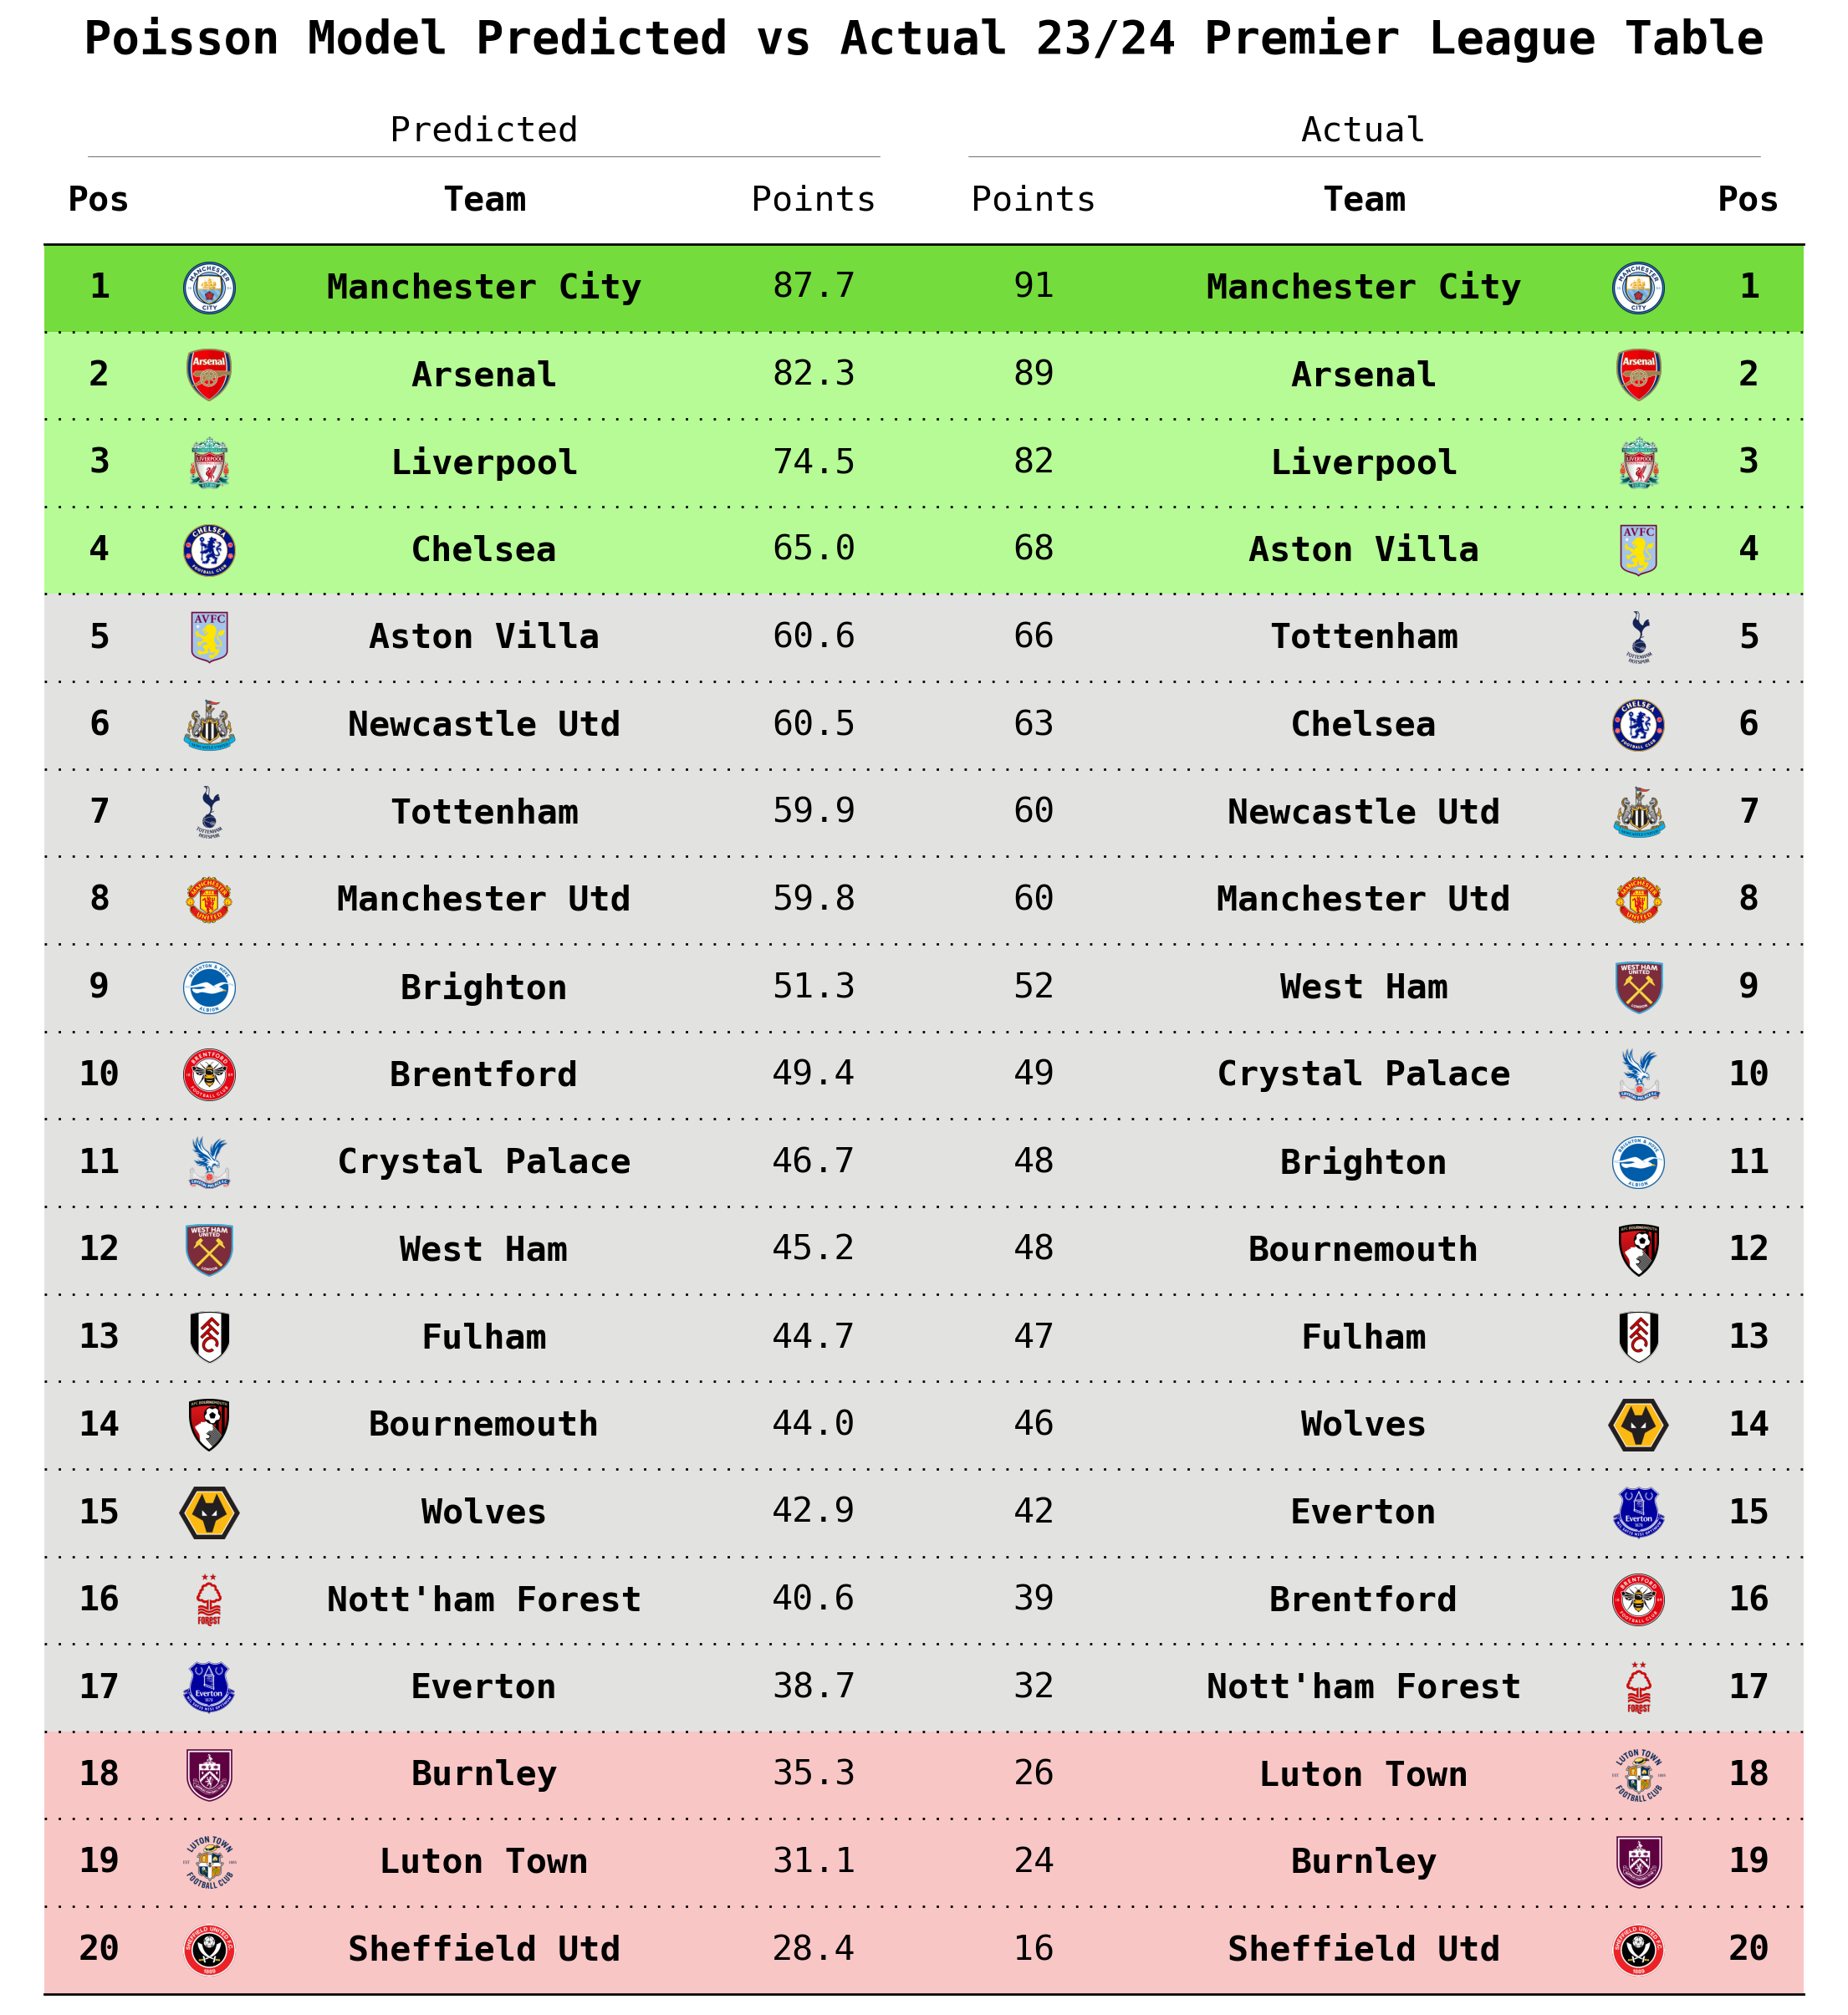

In [240]:
plot_table(df_comparison, col_defs, row_colors, bg_colour)

In [ ]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def plot_point_graph(df):
    
    df['Squared Error'] = df['Points Difference'] ** 2
    total_squared_error = df['Squared Error'].sum()
    mse = total_squared_error / len(df)

    plt.figure(figsize=(12, 8), dpi=200, facecolor='#FFFFFF')  

    for i, team in df.iterrows():
        badge = plt.imread(team['Badge'])
        plt.imshow(badge, extent=(team['Actual Points']-1.5, team['Actual Points']+1.5, team['Points']-2.5, team['Points']+2.5), aspect='auto', alpha=1)

    plt.plot([20, 91], [20, 91], color='#4E585F', linestyle='--', linewidth=1)

    # Add labels and title
    plt.xlabel('Actual Points', color='grey',weight='bold')  
    plt.ylabel('Predicted Points', color='grey',weight='bold')  
    plt.yticks([20,30,40,50,60,70,80,90],['20','30','40','50','60','70','80','90'], color='black')  
    plt.xticks([20,30,40,50,60,70,80,90],['20','30','40','50','60','70','80','90'],color='black')  
    plt.ylim(20,93)
    plt.xlim(14,93)

    plt.text(32, 72, 'Over Predicting', color='grey', fontsize=14, fontweight='bold', alpha=0.8)
    plt.text(60, 35, 'Under Predicting', color='grey', fontsize=14, fontweight='bold', alpha=0.8)

    plt.subplots_adjust(top=0.85, bottom=0.25)
    # Add text outside of the plot
    plt.text(0.01, 1.1, 'Comparison of Predicted and Actual Points', color='black', fontsize=20, weight='bold', ha='left', va='center',transform=plt.gca().transAxes)
    plt.text(0.01, 1.05, 'Premier League 23/24 Season | Data: @FBref', color='black', fontsize=8,ha='left', va='center',transform=plt.gca().transAxes)
    plt.text(0.5, 0.95, f'Mean Squared Error: {mse:.2f}', color='black', fontsize=10,weight = 'bold',ha='center', va='center',transform=plt.gca().transAxes,
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='black', boxstyle='round,pad=0.5'))
    # Set the plot background color to #141514
    plt.gca().set_facecolor('#FFFFFF')

    logo_image = plt.imread("C:\\Users\\George\\Documents\\Football Analytics\\Images\\Premier League_Logo.png")

    # Create an OffsetImage instance with the loaded image
    logo_offsetimage = OffsetImage(logo_image, zoom=0.13)  # Adjust the zoom value as needed

    # Create an AnnotationBbox instance and add it to the plot
    logo_box = AnnotationBbox(logo_offsetimage, (0.98, 1.14), xycoords='axes fraction', box_alignment=(1.0, 1.0), boxcoords="offset pixels")
    ax = plt.gca()
    ax.add_artist(logo_box)

    # Make the box invisible, but keep the image visible
    logo_box.patch.set_alpha(0)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('grey')
    ax.spines['bottom'].set_color('grey')

    plt.show()

In [ ]:
df = df_comparison
plot_point_graph(df)

KeyError: 'Points Difference'

In [ ]:
def get_table_position_probs(team_positions, num_iterations):
    pos_prob_df = pd.DataFrame.from_dict(team_positions)
    pos_prob_df = (pos_prob_df / num_iterations * 100).round(2)
    pos_prob_df.sort_index(inplace=True)
    pos_prob_df = pos_prob_df.T
    pos_prob_df.sort_values(by=1, ascending=False, inplace=True)
    pos_prob_df.fillna(0, inplace=True)
    pos_prob_df.index.name = 'Team'
    cum_pos_prob_df = pos_prob_df.copy()
    for x in cum_pos_prob_df.index:
        cum_pos_prob_df.loc[x] = cum_pos_prob_df.loc[x].cumsum()
    prob_pos_dict = {}
    for pos in cum_pos_prob_df.columns:
        prob_pos_dict[pos] = cum_pos_prob_df[pos].idxmax()
        cum_pos_prob_df.drop(prob_pos_dict[pos], inplace=True)
    pred_pos_df = pd.DataFrame(prob_pos_dict, index=[0])
    pred_pos_df = pred_pos_df.T
    pred_pos_df.rename(columns={0: 'Team'}, inplace=True)
    table_pred = pd.merge(pred_pos_df, pos_prob_df, on='Team')
    table_pred = table_pred.reset_index(drop=True)
    table_pred['POS'] = range(1,21)
    position = table_pred['POS']
    table_pred.drop(columns=['POS'], inplace=True)
    table_pred.insert(0, 'POS', position)
    table_pred['Badge'] = table_pred['Team'].apply(lambda x: f"C:/Users/George/Documents/Football Analytics/Team Logos/{x.lower()}_logo.png")
    table_pred = table_pred[['Team', 'Badge', 'POS', 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]]
    #table_pred.set_index(['Team','Position'], inplace=True)
    #table_pred.set_index('Team',inplace=True)
    return table_pred

def plot_table_position_probs(df, cmap, min_val, max_val):
    fig = plt.figure(figsize=(12, 6), dpi=200, facecolor='#F9F8F5')
    gs = fig.add_gridspec(1, 23)

    # Create axes for team names, positions, badges, and the heatmap
    ax_teams = fig.add_subplot(gs[0, 0:3])
    ax_pos = fig.add_subplot(gs[0, 4])
    ax_badges = fig.add_subplot(gs[0,3])
    ax_heatmap = fig.add_subplot(gs[0, 5:])

    # Plot team names, positions, and badges (you'll need to customize this part)
    from matplotlib import image as mpimg
    import matplotlib.colors as mcolors

    ax_teams.table(cellText=df['Team'].values.reshape(-1, 1), loc='center', cellLoc='right', fontsize=24,bbox=[0, 0, 1, 1], edges='open')
    pos_table = ax_pos.table(cellText=df['POS'].values.reshape(-1, 1), loc='center', cellLoc='center',bbox=[0, 0, 1, 1], edges='open')#, cellColours='grey')
    for i, team in df.iterrows():
        img = mpimg.imread(team['Badge'])
        ax_badges.imshow(img, extent=[0.25, 0.75, i+0.1, i+0.9], aspect='auto', origin='lower')
    for key, cell in pos_table.get_celld().items():
        cell.get_text().set_color('grey')
    ax_badges.set_ylim(len(df), 0)
    ax_badges.set_xlim(0, 1)
    ax_badges.axis('off')
    min_val = 0.001
    my_cmap = copy(cmap)
    my_cmap = mcolors.LinearSegmentedColormap.from_list('trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=0.1, b=1),
                                                        cmap(np.linspace(0.1, 1, 100)))
    ax_heatmap.set_facecolor('#F9F8F5')
    my_cmap.set_over("#F9F8F5")
    my_cmap.set_under("#F9F8F5")
    sns.heatmap(df.iloc[:, 3:], ax=ax_heatmap, cmap=my_cmap, annot=True, fmt='.1f', cbar=False, linewidths=2, linecolor='#F9F8F5', vmin=min_val, vmax=max_val)
    ax_heatmap.xaxis.tick_top() 
    for t in ax_heatmap.texts: # rotate x ticks
        t.set_weight('bold')
        t.set_fontsize(8)
        if float(t.get_text())>=1:
            t.set_text(t.get_text()) #if the value is greater than 0.4 then I set the text 
        else:
            t.set_text("")
    # Customize the appearance
    ax_heatmap.set_yticklabels([])
    #ax_heatmap.set_xlabel('Predicted Final League Position')
    plt.text(-0.25, 1.13, 'Predicted Final League Position', color='black', fontsize=16, weight='bold', ha='left', va='center', transform=plt.gca().transAxes)
    plt.text(-0.25, 1.08, 'Premier League 24/25 Season', color='black', fontsize=8, ha='left', va='center', transform=plt.gca().transAxes)
    plt.text(1, -0.05, 'Percentage probabilities of finishing in each position is shown. Only probabilities of at least 1% are labelled', color='black', fontsize=8, ha='right', va='center', transform=plt.gca().transAxes)
    # Add spines back to the heatmap
    ax_heatmap.spines['top'].set_visible(True)
    ax_heatmap.spines['top'].set_color('grey')
    ax_heatmap.spines['top'].set_linewidth(2)
    ax_heatmap.spines['left'].set_visible(True)
    ax_heatmap.spines['left'].set_color('grey')
    ax_heatmap.spines['left'].set_linewidth(2)
    ax_heatmap.tick_params(axis='both', which='both', length=0)
    for label in ax_heatmap.get_xticklabels():
        label.set_fontweight('bold')# Remove axes for team names, positions, and badges
    for ax in [ax_teams, ax_pos, ax_badges]:
        ax.axis('off')

    ax_pos.set_title('POS', fontsize=12, weight='bold', color='black', loc='center', pad=5)

    logo_image = plt.imread("C:\\Users\\George\\Documents\\Football Analytics\\Images\\Premier League_Logo.png")

    # Create an OffsetImage instance with the loaded image
    logo_offsetimage = OffsetImage(logo_image, zoom=0.11)  # Adjust the zoom value as needed

        # Create an AnnotationBbox instance and add it to the plot
    logo_box = AnnotationBbox(logo_offsetimage, (0.98, 1.16), xycoords='axes fraction', box_alignment=(1.0, 1.0), boxcoords="offset pixels")
    ax = plt.gca()
    ax.add_artist(logo_box)

        # Make the box invisible, but keep the image visible
    logo_box.patch.set_alpha(0)
    plt.tight_layout()
    plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Predicted 24-25 Table Probabilities.png", dpi=300, bbox_inches='tight')
    plt.show()

C:\Users\dmsta\AppData\Local\Temp\ipykernel_24496\375276438.py:103: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


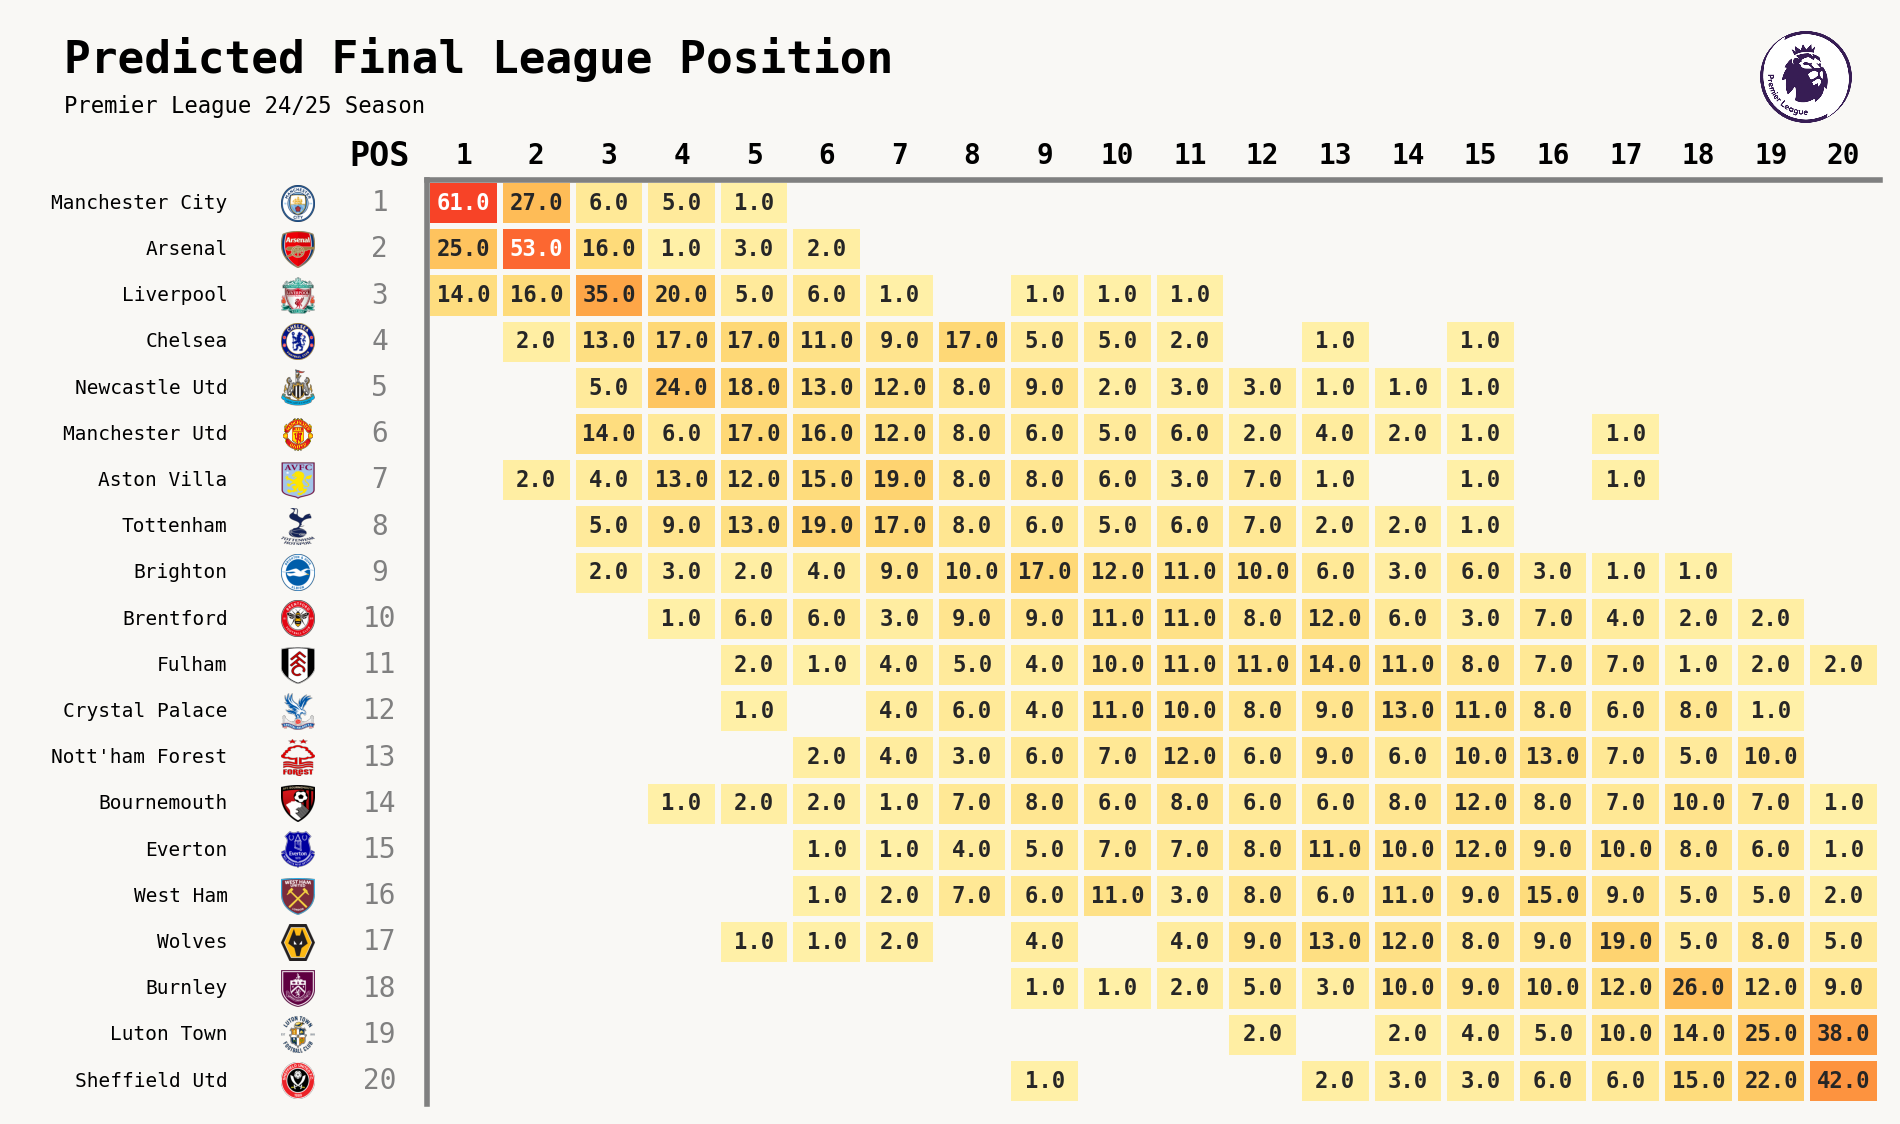

In [ ]:
min_val = 0.001
max_val = 100
cmap = plt.cm.YlOrRd
simulations = 100
table_pred = get_table_position_probs(team_positions, simulations)
plot_table_position_probs(table_pred, cmap, min_val, max_val)

In [ ]:
df = pd.read_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\Big Dataset.xlsx", index_col=0)

In [ ]:
df_future = df[df['season'] == 2024]
df_future.reset_index(drop=True, inplace=True)
forecast_df = pd.concat([test, df_future], axis=0)
forecast_df.reset_index(drop=True, inplace=True)
forecast_df = pd.concat([forecast_df, champ], axis=0)
forecast_df['home GD'] = forecast_df['home GF'] - forecast_df['away GF']
forecast_df['away GD'] = forecast_df['away GF'] - forecast_df['home GF']

In [ ]:
def simulate_game_future(home_goal_probs, away_goal_probs):
    home_goals = np.random.choice([0,1,2,3,4,5,6,7,8], p=home_goal_probs)
    away_goals = np.random.choice([0,1,2,3,4,5,6,7,8], p=away_goal_probs)
    if home_goals > away_goals:
        home_points = 3
        away_points = 0
    elif home_goals < away_goals:
        home_points = 0
        away_points = 3
    else:  
        home_points = 1
        away_points = 1
    return home_points, away_points, home_goals, away_goals

In [ ]:
def append_result(df, df_test, row, home_points, away_points, home_goals, away_goals):
    # Extract the values from df_test row only once
    ht_value = df_test.iloc[row]['HT']
    at_value = df_test.iloc[row]['AT']
    
    # Create the condition using numpy for faster comparison
    condition = (df['HT'].to_numpy() == ht_value) & \
                (df['AT'].to_numpy() == at_value) & \
                (df['season'].to_numpy() == 2024)
    
    # Prepare the update values as numpy arrays
    update_values = np.array([
        home_points, away_points, 
        home_goals, away_goals, 
        home_goals - away_goals, away_goals - home_goals, 
        home_goals, away_goals, 
        away_goals, home_goals, 
        home_goals - away_goals, away_goals - home_goals
    ])
    
    # Vectorized assignment for the selected columns
    df.loc[condition, ['home points', 'away points', 'home GF', 'away GF', 'home GD', 
                       'away GD', 'HT GS', 'AT GS', 'HT GC', 'AT GC', 'HT AdjGD', 
                       'AT AdjGD']] = update_values
    
    return df


def update_form2(forecast_df):
    # Separate the data into home and away
    home_df = forecast_df[['HT', 'season','date', 'home points','home GF','away GF']].rename(columns={'HT': 'Team', 'season':'season','date':'date', 'home points': 'points', 'home GF': 'GF', 'away GF': 'GA'})
    away_df = forecast_df[['AT', 'season','date', 'away points','away GF', 'home GF']].rename(columns={'AT': 'Team', 'season':'season','date':'date', 'away points': 'points', 'away GF': 'GF', 'home GF': 'GA'})
    home_df = home_df.sort_values(by=['Team','season','date'])
    away_df = away_df.sort_values(by=['Team','season','date'])

    home_df['HT Home GF form 10'] = home_df.groupby('Team')['GF'].rolling(window=10, closed='left').mean().reset_index(0, drop=True)
    away_df['AT Away GF form 10'] = away_df.groupby('Team')['GF'].rolling(window=10, closed='left').mean().reset_index(0, drop=True)
    home_df['HT Home GA form 10'] = home_df.groupby('Team')['GA'].rolling(window=10, closed='left').mean().reset_index(0, drop=True)
    away_df['AT Away GA form 10'] = away_df.groupby('Team')['GA'].rolling(window=10, closed='left').mean().reset_index(0, drop=True)
    home_df['HT Home points form 10'] = home_df.groupby('Team')['points'].rolling(window=10, closed='left').mean().reset_index(0, drop=True)
    away_df['AT Away points form 10'] = away_df.groupby('Team')['points'].rolling(window=10, closed='left').mean().reset_index(0, drop=True)
    home_df = home_df.drop_duplicates(subset=['Team','season','date'])
    away_df = away_df.drop_duplicates(subset=['Team','season','date'])

    # Combine home and away into a single DataFrame
    combined_df = pd.concat([home_df, away_df], ignore_index=True)
    
    # Sort by team and game week
    combined_df = combined_df.sort_values(by=['Team','season','date'])

    # Calculate rolling average of goals for each team
    combined_df['Points form 5'] = combined_df.groupby('Team')['points'].rolling(window=5, closed='left').mean().reset_index(0, drop=True)

    # Optionally, merge the rolling averages back to the original DataFrame
    forecast_df.drop(columns=['HT points form 5', 'AT points form 5', 'HT Home GF form 10', 'AT Away GF form 10', 'HT Home GA form 10', 'AT Away GA form 10', 'HT Home points form 10', 'AT Away points form 10'], errors='ignore', inplace=True)
    forecast_df = forecast_df.merge(combined_df[['Team', 'season','date', 'Points form 5','HT Home GF form 10', 'HT Home GA form 10', 'HT Home points form 10']], left_on=['HT','season','date'], right_on=['Team','season', 'date'], how='left').rename(columns={'Points form 5': 'HT points form 5'}).drop(columns=['Team'])
    forecast_df = forecast_df.merge(combined_df[['Team', 'season','date', 'Points form 5', 'AT Away GF form 10', 'AT Away GA form 10', 'AT Away points form 10']], left_on=['AT','season','date'], right_on=['Team','season', 'date'], how='left').rename(columns={'Points form 5': 'AT points form 5'}).drop(columns=['Team'])
    forecast_df = forecast_df.drop_duplicates(subset=['HT','AT','season','date'])
    forecast_df = forecast_df.sort_values(by=['season','date'])
    forecast_df.reset_index(drop=True, inplace=True)

    # Display the updated DataFrame with rolling averages
    df_future = forecast_df[forecast_df['season'] == 2024]
    return df_future

def rolling_averages(group, number, cols, new_cols):
    group = group.sort_values("date")
    rolling_stats = group[cols].rolling(number, closed='left').mean()
    group[new_cols] = rolling_stats
    #group = group.dropna(subset=new_cols)
    return group

def update_goal_form(forecast_df, number, cols, home_cols, away_cols):
    forecast_df = forecast_df.groupby('HT').apply(lambda x: rolling_averages(x, number,cols, home_cols))
    forecast_df = forecast_df.groupby('AT').apply(lambda x: rolling_averages(x, number,cols, away_cols))
    forecast_df = forecast_df.droplevel('HT')
    forecast_df = forecast_df.droplevel('AT')
    return forecast_df

In [ ]:
predictors = ['HT AdjGD form 5', 'AT AdjGD form 5', 'HT Home GS form 10', 
              'HT Home GC form 10', 'AT Away GS form 10', 'AT Away GC form 10',
                'HT prev points','AT prev points','HT Market Value', 'AT Market Value']

In [ ]:
def update_form(forecast_df):
    # Define a dictionary for renaming columns to avoid repeating the same operation
    rename_home = {'HT': 'Team', 'home points': 'points', 'home GF': 'GF', 'away GF': 'GA', 'home GD': 'GD', 'HT GS': 'GS', 'HT GC': 'GC', 'HT AdjGD': 'AdjGD'}
    rename_away = {'AT': 'Team', 'away points': 'points', 'away GF': 'GF', 'home GF': 'GA', 'away GD': 'GD', 'AT GS': 'GS', 'AT GC': 'GC', 'AT AdjGD': 'AdjGD'}

    # Create home_df and away_df in a single step with column selection and renaming
    home_df = forecast_df[['HT', 'season', 'date', 'home points', 'home GF', 'away GF', 'home GD', 'HT GS', 'HT GC', 'HT AdjGD']].rename(columns=rename_home)
    away_df = forecast_df[['AT', 'season', 'date', 'away points', 'away GF', 'home GF', 'away GD', 'AT GS', 'AT GC', 'AT AdjGD']].rename(columns=rename_away)
    home_df.sort_values(by=['Team', 'season', 'date'], inplace=True)
    away_df.sort_values(by=['Team', 'season', 'date'], inplace=True)

    home_drop_cols = []
    away_drop_cols = []

    window = 10

    for i in predictors:
        # Split the string once and extract the relevant part
        parts = i.split(' ')
        column_name = parts[2]

        if "Home" in i:
            # Calculate rolling mean once per team and assign to all relevant columns
            rolling_means = home_df.groupby('Team')[column_name].rolling(window=window, closed='left').mean()
            home_df[i] = rolling_means.reset_index(level=0, drop=True)
            home_drop_cols.append(i)
        elif "Away" in i:
            # Same for away_df
            rolling_means = away_df.groupby('Team')[column_name].rolling(window=window, closed='left').mean()
            away_df[i] = rolling_means.reset_index(level=0, drop=True)
            away_drop_cols.append(i)
    
    home_df.drop_duplicates(subset=['Team','season','date'], inplace=True)
    away_df.drop_duplicates(subset=['Team','season','date'], inplace=True)

    # Combine home and away into a single DataFrame
    combined_df = pd.concat([home_df, away_df], ignore_index=True)
    
    # Sort by team and game week
    combined_df.sort_values(by=['Team','season','date'], inplace=True)

    # Calculate rolling average of goals for each team
    
    merge_cols = ['Team', 'season','date']
    temp_cols = []
    drop_cols = []

    split_values = [i.split(' ') for i in predictors]

    # Iterate over predictors and precomputed splits
    for split in split_values:
        col_name = (' '.join(split[1:]))
        if split[2] == 'form':
            # Use the column name directly without splitting again
            combined_df[col_name] = combined_df.groupby('Team')[split[1]].rolling(window=5, closed='left').mean().reset_index(0, drop=True)
            drop_cols.append(' '.join(split))
            temp_cols.append(col_name)
    temp_cols = list(set(temp_cols))
    merge_cols = merge_cols + temp_cols
    
    # Optionally, merge the rolling averages back to the original DataFrame
    forecast_df.drop(columns=drop_cols+home_drop_cols+away_drop_cols, errors='ignore', inplace=True)
    rename_map = {
    'points form 5': 'HT points form 5',
    'GD form 5': 'HT GD form 5',
    'AdjGD form 5': 'HT AdjGD form 5'
    }
    forecast_df = forecast_df.merge(combined_df[merge_cols+home_drop_cols], left_on=['HT','season','date'], right_on=['Team','season', 'date'], how='left').rename(columns=rename_map).drop(columns=['Team'])
    rename_map = {
    'points form 5': 'AT points form 5',
    'GD form 5': 'AT GD form 5',
    'AdjGD form 5': 'AT AdjGD form 5'
    }
    forecast_df = forecast_df.merge(combined_df[merge_cols+away_drop_cols], left_on=['AT','season','date'], right_on=['Team','season', 'date'], how='left').rename(columns=rename_map).drop(columns=['Team'])
    forecast_df.drop_duplicates(subset=['HT','AT','season','date'], inplace=True)
    forecast_df.sort_values(by=['season','date'], inplace=True)
    forecast_df.reset_index(drop=True, inplace=True)
    
    # Display the updated DataFrame with rolling averages
    df_future = forecast_df[forecast_df['season'] == 2024]
    return df_future

In [ ]:
def simulate_all_future_games(forecast_df, df_future, home_goal_model, away_goal_model, home_predictors, away_predictors, num_iterations, home_trainX, away_trainX):
    teams = df_future['HT'].unique()
    team_positions = {team: Counter() for team in teams}
    total_points = {team: 0 for team in teams}
    total_goals_scored = {team: 0 for team in teams}
    total_goals_conceded = {team: 0 for team in teams}
    home_scaler = StandardScaler()
    home_scaler.fit(home_trainX)
    away_scaler = StandardScaler()
    away_scaler.fit(away_trainX)
    for _ in range(num_iterations):
        team_points = {team: 0 for team in teams}
        team_goals_scored = {team: 0 for team in teams}
        team_goals_conceded = {team: 0 for team in teams}
        for gameweek in range(38):
            df_test = df_future.copy()
            df_test.reset_index(drop=True, inplace=True)
            home_df_testX = df_test[home_predictors]
            away_df_testX = df_test[away_predictors]
            home_df_testX_scaled = home_scaler.transform(home_df_testX, copy=True)
            away_df_testX_scaled = away_scaler.transform(away_df_testX, copy=True)
            pred_home_goals = home_goal_model.predict(home_df_testX_scaled[gameweek*10:gameweek*10+10]) * 1.0435
            pred_away_goals = away_goal_model.predict(away_df_testX_scaled[gameweek*10:gameweek*10+10]) * 1.0435
            future_home_goals_perc = pd.DataFrame([calculate_goal_probabilities(goals) for goals in pred_home_goals])
            future_away_goals_perc = pd.DataFrame([calculate_goal_probabilities(goals) for goals in pred_away_goals])
            for game in range(10):
                home_points, away_points, home_goals, away_goals = simulate_game_future(future_home_goals_perc.iloc[game], future_away_goals_perc.iloc[game])            
                actual_game = game + gameweek*10
                team_points[df_test.iloc[actual_game]['HT']] += home_points
                team_points[df_test.iloc[actual_game]['AT']] += away_points
                team_goals_scored[df_test.iloc[actual_game]['HT']] += home_goals
                team_goals_scored[df_test.iloc[actual_game]['AT']] += away_goals
                team_goals_conceded[df_test.iloc[actual_game]['HT']] += away_goals
                team_goals_conceded[df_test.iloc[actual_game]['AT']] += home_goals
                forecast_df = append_result(forecast_df, df_test, actual_game, home_points, away_points, home_goals, away_goals)
            df_future = update_form(forecast_df) 
        total_points = {team: total_points[team] + team_points[team] for team in teams}
        total_goals_scored = {team: total_goals_scored[team] + team_goals_scored[team] for team in teams}
        total_goals_conceded = {team: total_goals_conceded[team] + team_goals_conceded[team] for team in teams}
        sorted_teams = sorted(team_points.items(), key=lambda x: x[1], reverse=True)
        for position, (team, _) in enumerate(sorted_teams, start=1):
            team_positions[team][position] += 1
    sorted_table = sorted(total_points.items(), key=lambda x: x[1], reverse=True)
    average_goals_scored = pd.DataFrame(total_goals_scored.items(), columns=['Team', 'Goals Scored'])
    average_goals_conceded = pd.DataFrame(total_goals_conceded.items(), columns=['Team', 'Goals Conceded'])
    average_points = pd.DataFrame(sorted_table, columns=['Team', 'Points'])
    average_points = average_points.merge(average_goals_scored, on='Team', how='left')
    average_points = average_points.merge(average_goals_conceded, on='Team', how='left')
    average_points['Points'] = average_points['Points'] / num_iterations
    average_points['Goals Scored'] = average_points['Goals Scored'] / num_iterations
    average_points['Goals Conceded'] = average_points['Goals Conceded'] / num_iterations
    average_points['Goal Difference'] = average_points['Goals Scored'] - average_points['Goals Conceded']
    average_points['Position'] = average_points.index + 1
    average_points_table = average_points[['Position','Team', 'Points', 'Goals Scored', 'Goals Conceded', 'Goal Difference']]

    return team_positions, average_points_table

In [ ]:
simulations = 10000
future_positions, future_points_table = simulate_all_future_games(forecast_df, df_future, home_goal_model, away_goal_model, home_predictors, away_predictors, simulations, home_trainX, away_trainX)

In [ ]:
future_points_table.to_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\Future Points Table Alpha = 0.65.xlsx")
#future_positions.to_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\Future Positions.xlsx")

In [ ]:
from line_profiler import LineProfiler
import random

#lp = LineProfiler()
#lp_wrapper = lp(simulate_all_future_games)
#lp_wrapper(forecast_df, df_future, home_goal_model, away_goal_model, predictors, simulations, home_trainX)
#lp.print_stats()

In [ ]:
col_defs = [
    ColumnDefinition(
        name="Predicted Pos",
        textprops={"ha" : "center"},
        width=0.3,
        title="Pos"
    ), 
    ColumnDefinition(
        name="Badge",
        textprops={"ha" : "center", "va" : "center", "color" : bg_colour},
        width=0.3,
        plot_fn=image,
    ),
    ColumnDefinition(
        name="Team",
        textprops={"ha" : "center","weight" : "bold"},
        width=0.8,
    ),
    ColumnDefinition(
        name="Goals Scored",
        title="GF",
        #group="Predicted",
        textprops={"ha" : "center"},
        width=0.4,
    ),
    ColumnDefinition(
        name="Goals Conceded",
        title="GA",
        #group="Predicted",
        textprops={"ha" : "center"},
        width=0.4,
    ),
    ColumnDefinition(
        name="Goal Difference",
        title="GD",
        #group="Predicted",
        textprops={"ha" : "center"},
        width=0.4,
    ),
    ColumnDefinition(
        name="Points",
        #group="Predicted",
        textprops={"ha" : "center","weight" : "bold"},
        width=0.4,
    )
]

In [ ]:
future_points_table.rename(columns={'Position': 'Predicted Pos'}, inplace=True)

In [ ]:
def plot_future_table(df, col_defs, row_colors, bg_colour):
    fig, ax = plt.subplots(figsize=(14, 15), dpi=200)
    fig.set_facecolor(bg_colour)
    ax.set_facecolor(bg_colour)

    table = Table(
        df,
        column_definitions=col_defs,
        index_col="Predicted Pos",
        row_dividers=True,
        row_divider_kw={"linewidth" : 1, "linestyle" : (0, (1,5))},
        footer_divider=True,
        textprops={"fontsize" : 15},
        ax=ax,
    )

    ax.set_title("Average Predicted 24/25 Premier League Table", fontsize=20, weight="bold", color=text_colour)
    # CHANGE COLORS FOR RELEGATION, TITLE ETC

    row_colors = row_colors
    for idx in range(0,20):
        table.rows[idx].set_facecolor(row_colors["even"])
    #for idx in range(1,20,2):
     #   table.rows[idx].set_facecolor(row_colors["odd"])
    for idx in range(0,1):
        table.rows[idx].set_facecolor(row_colors["top1"])
    for idx in range(1,4):
        table.rows[idx].set_facecolor(row_colors["top4"])
    for idx in range(17,20):
        table.rows[idx].set_facecolor(row_colors["relegation"])
    
    plt.savefig(r"C:\Users\George\Documents\University\Masters\DISS\Predicted 24-25 Table.png", dpi=300)

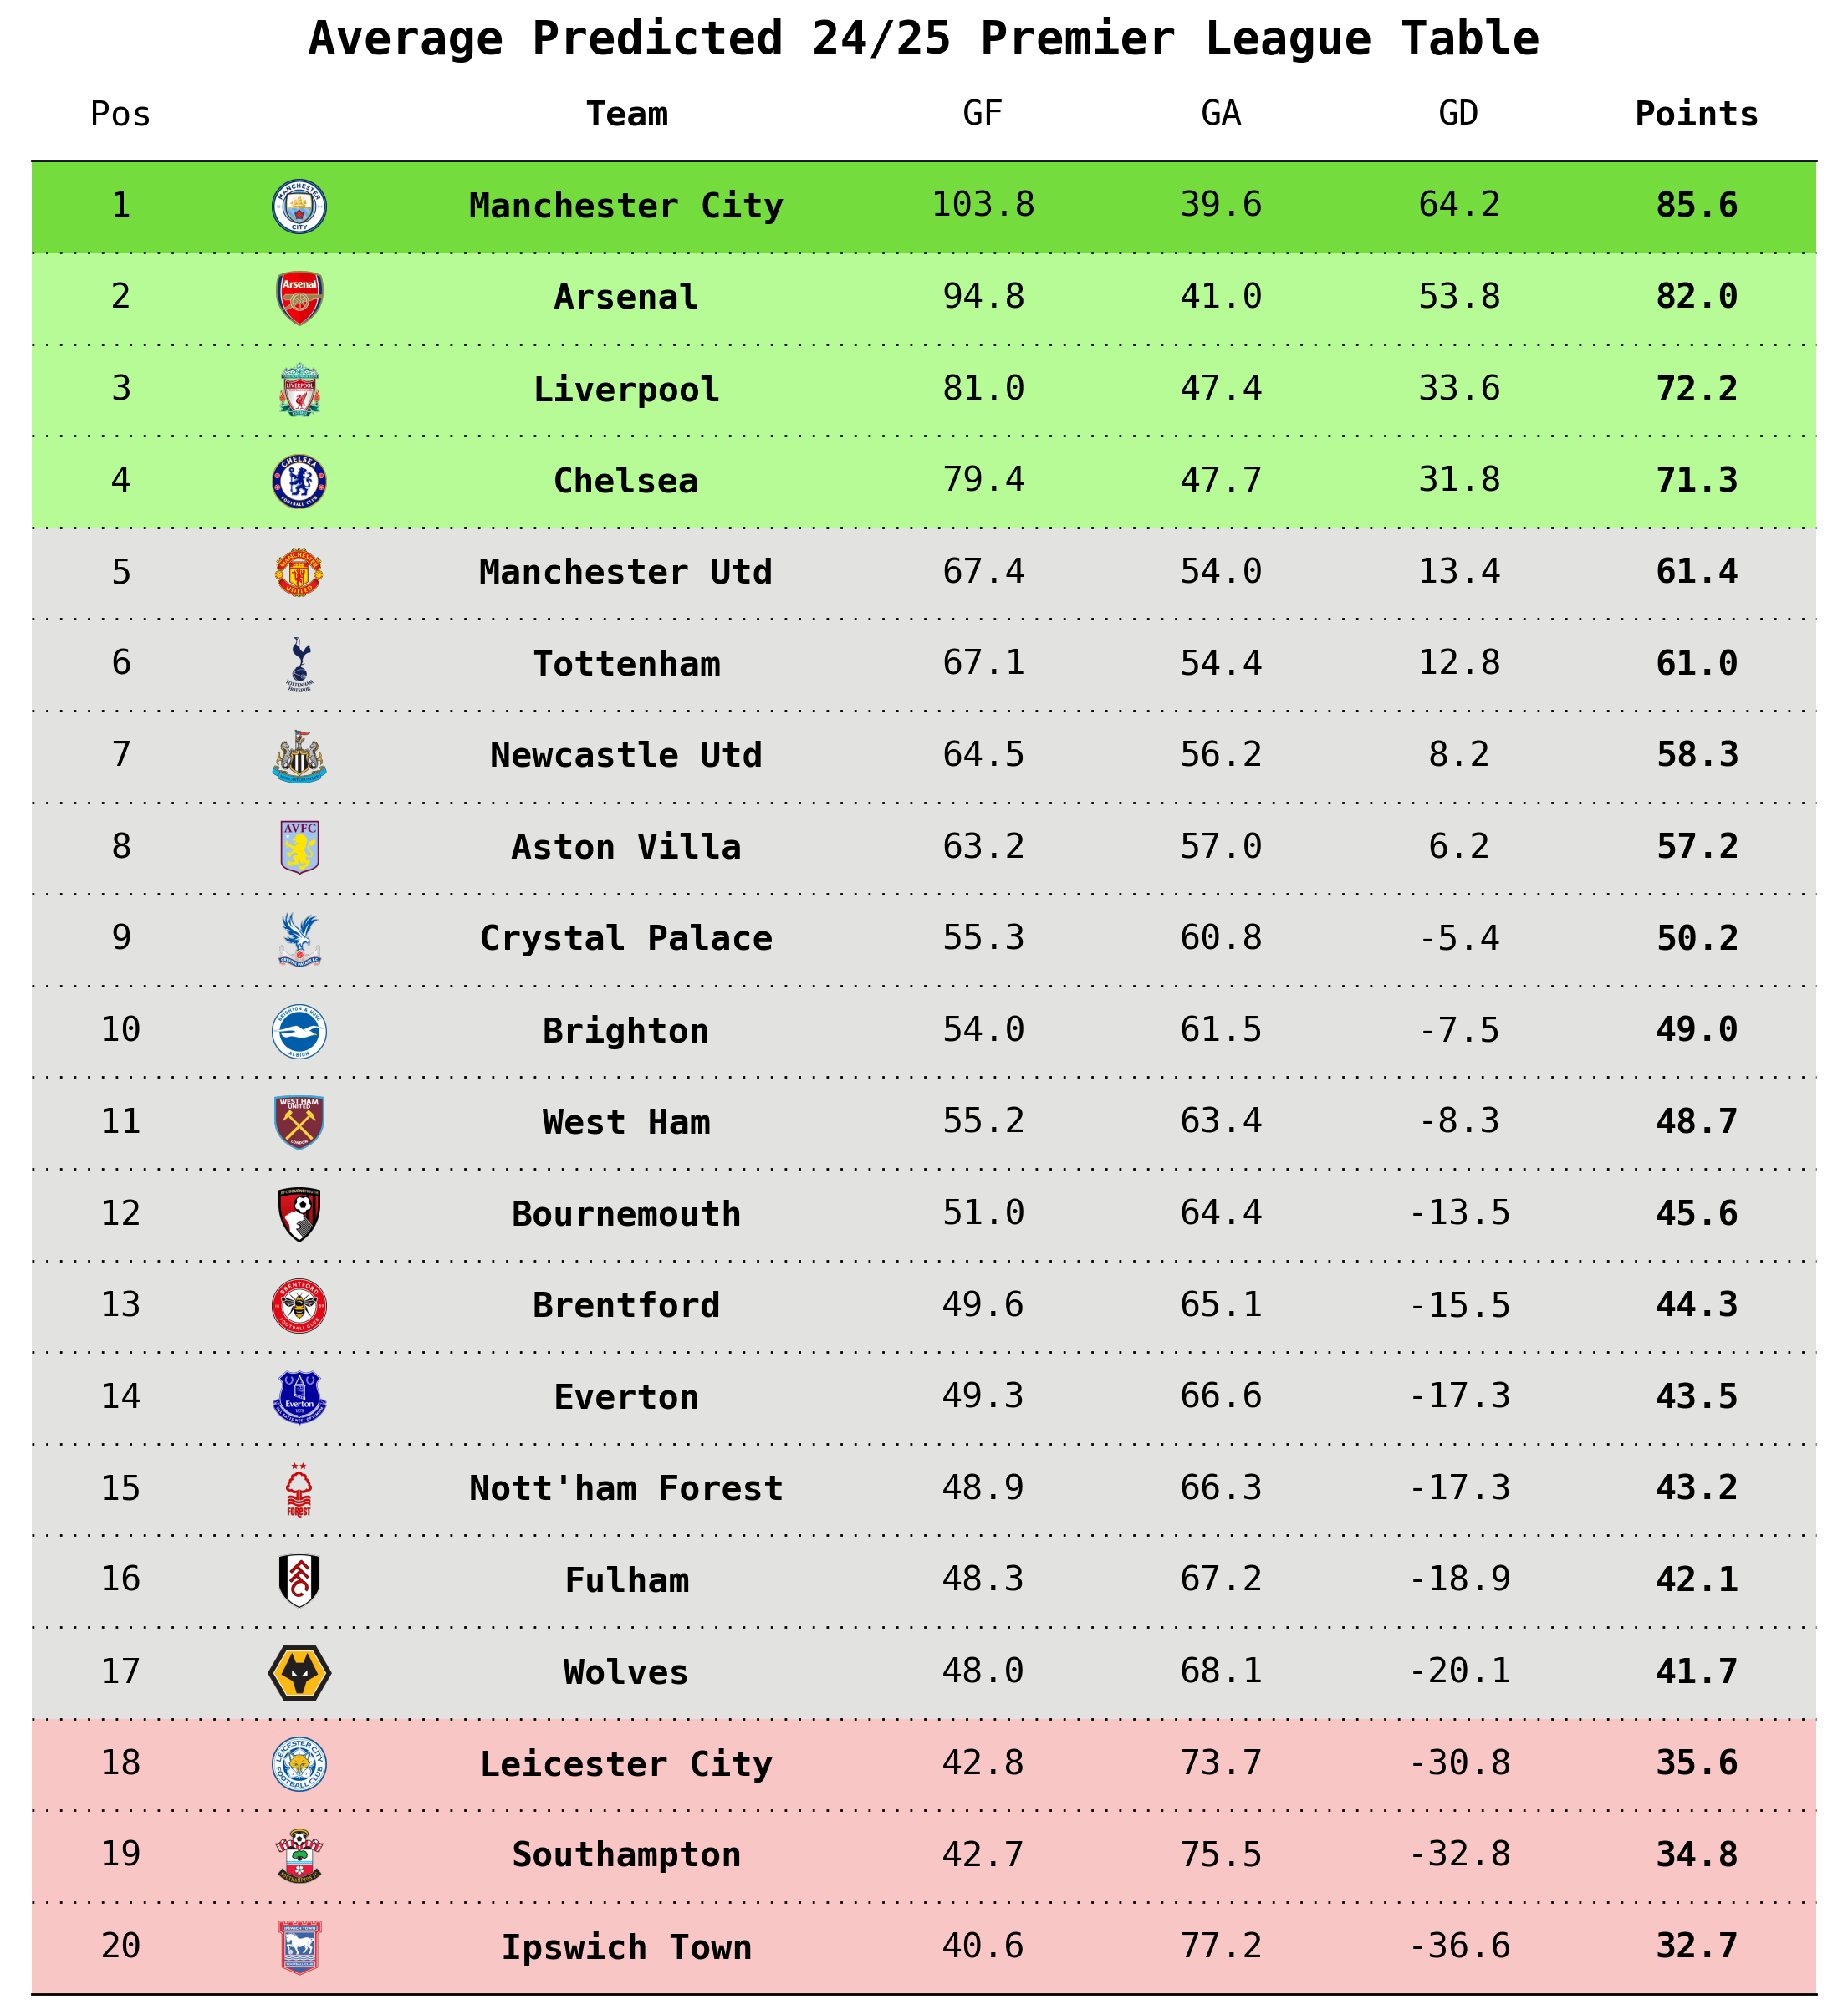

In [ ]:
future_points_table['Badge'] = future_points_table['Team'].apply(lambda x: f"C:/Users/George/Documents/Football Analytics/Team Logos/{x.lower()}_logo.png")
future_points_table_sorted = future_points_table[['Predicted Pos','Badge','Team', 'Goals Scored', 'Goals Conceded', 'Goal Difference', 'Points']]
future_points_table_sorted['Goal Difference'] = future_points_table_sorted['Goal Difference'].round(1)
future_points_table_sorted['Points'] = future_points_table_sorted['Points'].round(1)
future_points_table_sorted['Goals Scored'] = future_points_table_sorted['Goals Scored'].round(1)
future_points_table_sorted['Goals Conceded'] = future_points_table_sorted['Goals Conceded'].round(1)
plot_future_table(future_points_table_sorted, col_defs, row_colors, bg_colour)

C:\Users\dmsta\AppData\Local\Temp\ipykernel_24496\3756815405.py:104: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


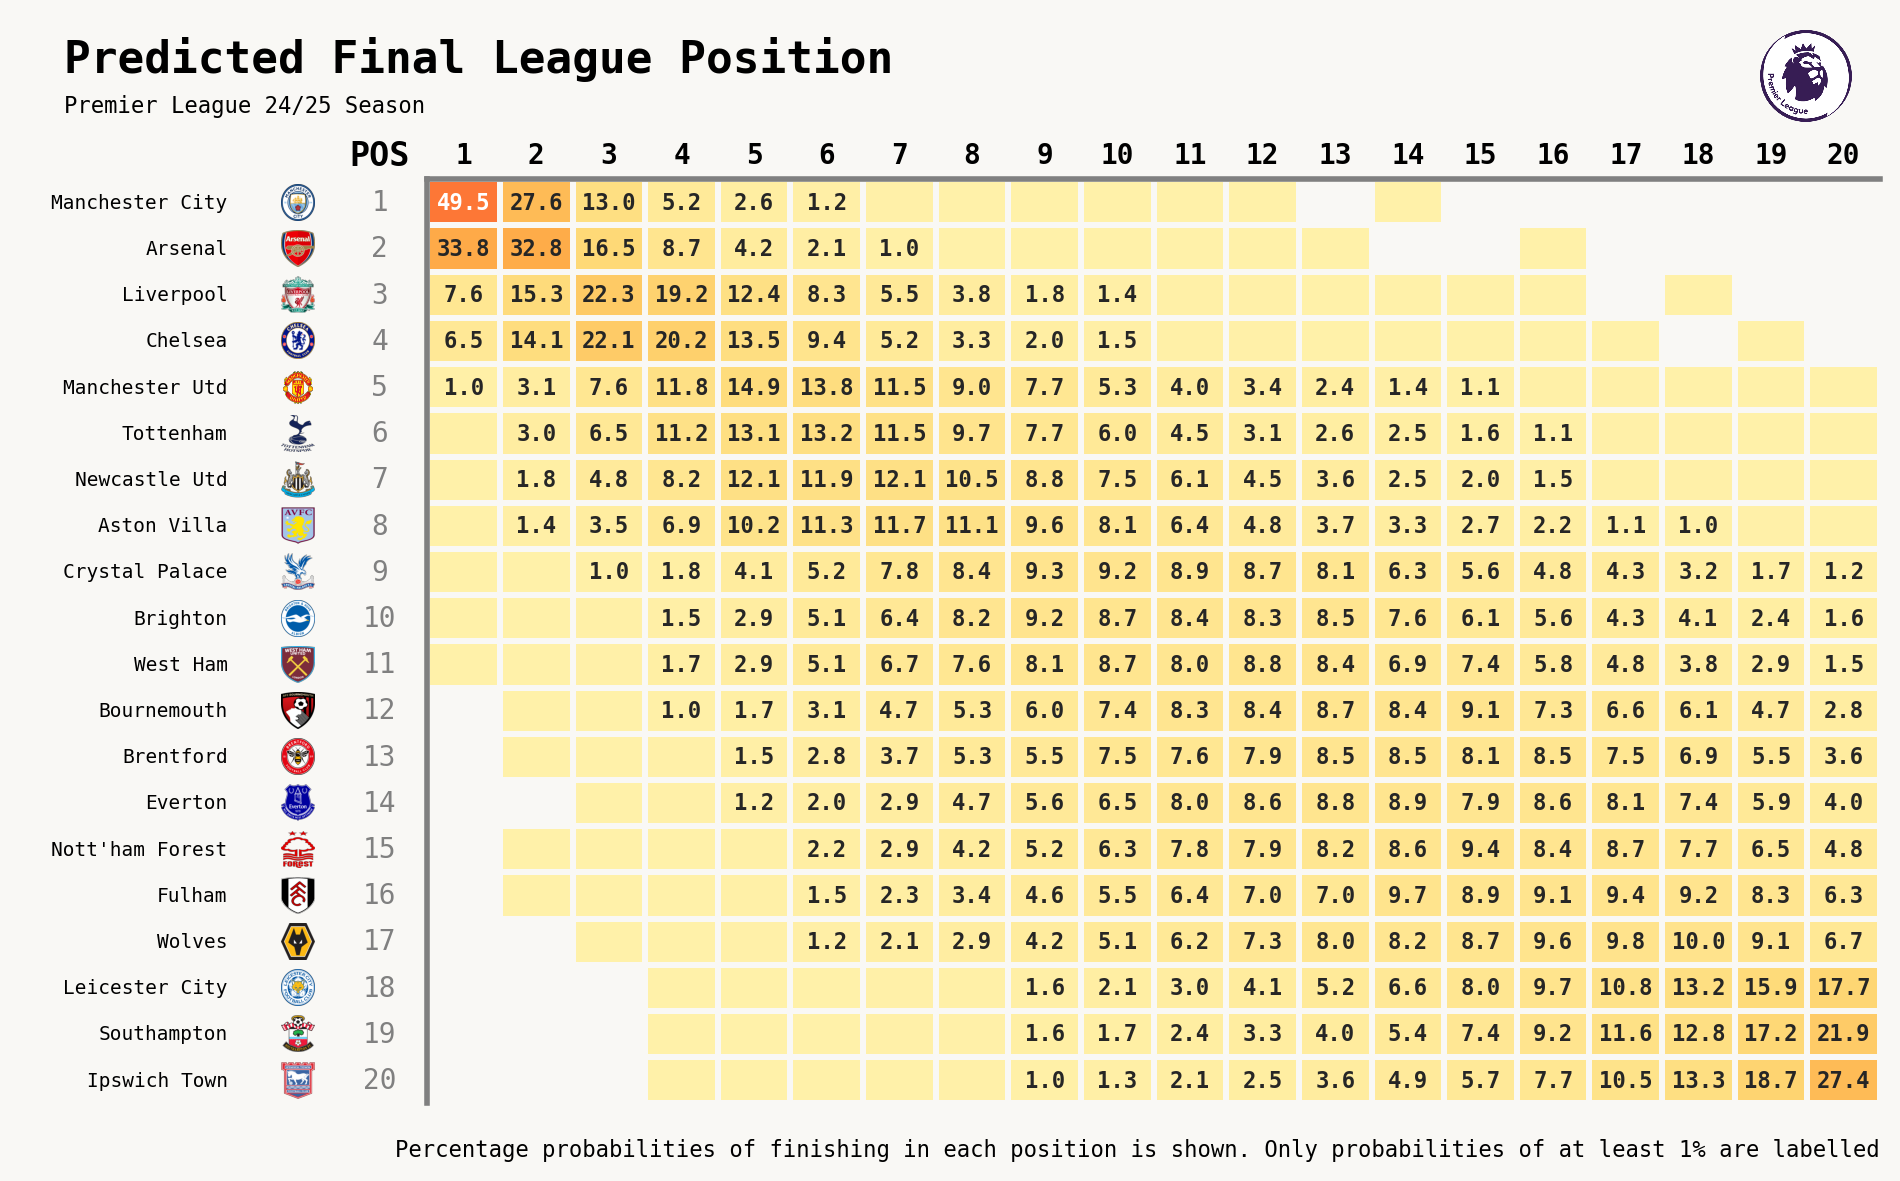

In [ ]:
max_val = 100
min_val = 0.001
cmap = plt.cm.YlOrRd
simulations = 5000
pred_future_table = get_table_position_probs(future_positions, simulations)
pred_future_table = pred_future_table.merge(future_points_table_sorted[['Predicted Pos', 'Team']], on='Team')
pred_future_table.sort_values(by='Predicted Pos', inplace=True)
pred_future_table['POS'] = range(1,21)
pred_future_table.drop(columns='Predicted Pos', inplace=True)
pred_future_table.reset_index(drop=True, inplace=True)
pred_future_table['Badge'] = pred_future_table['Team'].apply(lambda x: f"C:/Users/George/Documents/Football Analytics/Team Logos/{x.lower()}_logo.png")
plot_table_position_probs(pred_future_table, cmap, min_val, max_val)

In [ ]:
pred_future_table.to_excel(r"C:\Users\George\Documents\University\Masters\DISS\Datasets\Predicted 24-25 Position Probs.xlsx")